Practical No. 05: Image Generation using Pretrained Stable Diffusion


Aim: Generate images from text prompts using a pretrained Stable Diffusion model and study the effect of inference steps, guidance scale, and sampling methods.



Run in Google Colab with GPU: Runtime → Change runtime type → T4 GPU (if available).



Run each code cell from top to bottom. The first model download may take several minutes.

**NAME :- RAGAV SHARMA**

**BATCH:-A2/AIML**

**PRN :- 202401110012**

# **Install required libraries**

---



In [ ]:
!pip -q install -U diffusers transformers accelerate safetensors pandas matplotlib Pillow

 Import libraries and configure GPU

In [ ]:
import os
import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

from diffusers import (
    StableDiffusionPipeline,
    PNDMScheduler,
    DDIMScheduler,
    EulerDiscreteScheduler,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = "cpu"
    print("GPU not found. CPU generation will be much slower.")

# Reproducibility settings
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


# **Connect Google Drive and create folders**

In [ ]:
USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE_DIR = "/content/drive/MyDrive/Stable_Diffusion_Practical_05"
    except ImportError:
        print("Google Colab not detected. Saving locally.")
        BASE_DIR = "Stable_Diffusion_Practical_05"
    except Exception as e:
        print("Drive mounting failed:", e)
        BASE_DIR = "Stable_Diffusion_Practical_05"
else:
    BASE_DIR = "Stable_Diffusion_Practical_05"

IMAGE_DIR = os.path.join(BASE_DIR, "generated_images")
RESULT_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(IMAGE_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("Images will be saved to:", IMAGE_DIR)
print("Results will be saved to:", RESULT_DIR)

Mounted at /content/drive
Images will be saved to: /content/drive/MyDrive/Stable_Diffusion_Practical_05/generated_images
Results will be saved to: /content/drive/MyDrive/Stable_Diffusion_Practical_05/results


# **Load the pretrained Stable Diffusion model**

In [ ]:
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

try:
    dtype = torch.float16 if device == "cuda" else torch.float32

    pipe = StableDiffusionPipeline.from_pretrained(
        MODEL_ID,
        torch_dtype=dtype,
        safety_checker=None
    )

    pipe = pipe.to(device)

    # Memory-saving settings
    pipe.enable_attention_slicing()

    if device == "cuda":
        try:
            pipe.enable_vae_slicing()
        except Exception:
            pass

    print("Stable Diffusion model loaded successfully.")

except Exception as e:
    raise RuntimeError(
        "Could not load the Stable Diffusion model. "
        "Check your internet connection, model access, "
        "installed library versions, and available memory.\n"
        f"Original error: {e}"
    )

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Stable Diffusion model loaded successfully.


# **Define prompts and image generation function**

  0%|          | 0/30 [00:00<?, ?it/s]

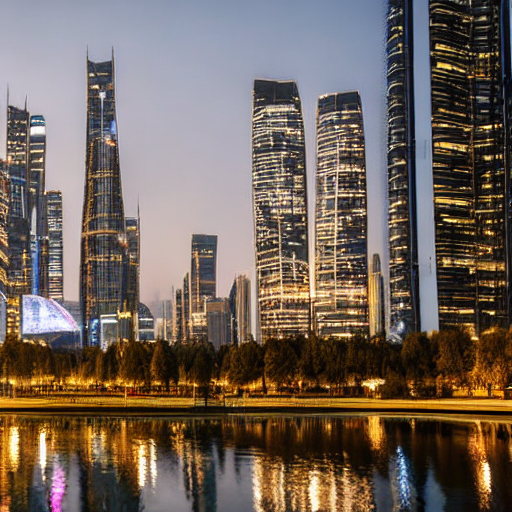

{'scheduler': 'Default', 'steps': 30, 'guidance_scale': 7.5, 'seed': 42, 'generation_time_seconds': 9.586, 'image_width': 512, 'image_height': 512, 'image_path': '/content/drive/MyDrive/Stable_Diffusion_Practical_05/generated_images/Default_steps30_guidance7.5_seed42.png', 'status': 'Success'}


In [ ]:
PROMPT = (
    "A highly detailed photograph of a futuristic city beside a lake, "
    "beautiful architecture, cinematic lighting, realistic reflections, "
    "professional photography, sharp focus, 4K detail"
)

NEGATIVE_PROMPT = (
    "blurry, low quality, distorted objects, deformed architecture, "
    "extra limbs, duplicate objects, watermark, text, noise, artifacts"
)

RESULTS = []

def generate_image(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    steps=30,
    guidance=7.5,
    seed=42,
    scheduler_name="Default",
    save=True
):
    """Generate one image and return its image and experiment metadata."""

    generator = torch.Generator(device=device).manual_seed(int(seed))

    try:
        if device == "cuda":
            torch.cuda.empty_cache()

        start_time = time.perf_counter()

        result = pipe(
            prompt=prompt,
            negative_prompt=negative_prompt,
            num_inference_steps=int(steps),
            guidance_scale=float(guidance),
            generator=generator,
            height=512,
            width=512
        )

        elapsed = time.perf_counter() - start_time
        image = result.images[0]

        filename = (
            f"{scheduler_name}_steps{steps}_"
            f"guidance{guidance}_seed{seed}.png"
        )

        filepath = os.path.join(IMAGE_DIR, filename)

        if save:
            image.save(filepath)

        record = {
            "scheduler": scheduler_name,
            "steps": int(steps),
            "guidance_scale": float(guidance),
            "seed": int(seed),
            "generation_time_seconds": round(elapsed, 3),
            "image_width": image.width,
            "image_height": image.height,
            "image_path": filepath if save else None,
            "status": "Success"
        }

        RESULTS.append(record)

        return image, record

    except torch.cuda.OutOfMemoryError:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()

        print(
            "GPU memory is insufficient. Try fewer inference steps, "
            "a smaller image size, or a GPU with more memory."
        )
        return None, {
            "scheduler": scheduler_name,
            "steps": steps,
            "guidance_scale": guidance,
            "seed": seed,
            "status": "CUDA out of memory"
        }

    except Exception as e:
        print("Image generation failed:", str(e))
        return None, {
            "scheduler": scheduler_name,
            "steps": steps,
            "guidance_scale": guidance,
            "seed": seed,
            "status": str(e)
        }


image, info = generate_image()

if image is not None:
    display(image)
    print(info)

# ** Experiment 1: Effect of inference steps**

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

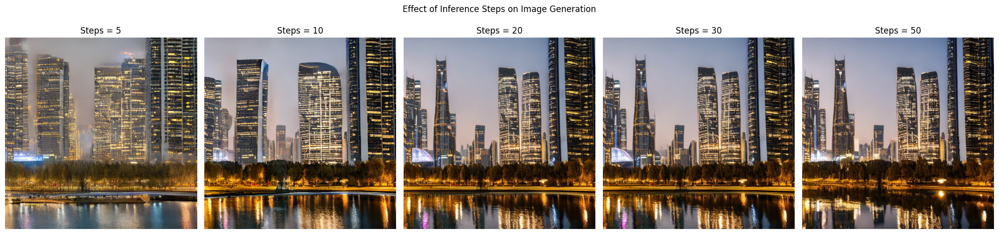

,scheduler,steps,guidance_scale,seed,generation_time_seconds,image_width,image_height,image_path,status
0,Default,5,7.5,42,1.473,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
1,Default,10,7.5,42,2.345,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
2,Default,20,7.5,42,4.281,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
3,Default,30,7.5,42,6.765,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
4,Default,50,7.5,42,10.298,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success


In [ ]:
STEP_VALUES = [5, 10, 20, 30, 50]

step_images = []
step_records = []

for steps in STEP_VALUES:
    image, record = generate_image(
        steps=steps,
        guidance=7.5,
        seed=42,
        scheduler_name="Default"
    )

    if image is not None:
        step_images.append((steps, image))
        step_records.append(record)

fig, axes = plt.subplots(1, len(step_images), figsize=(20, 5))

if len(step_images) == 1:
    axes = [axes]

for ax, (steps, img) in zip(axes, step_images):
    ax.imshow(img)
    ax.set_title(f"Steps = {steps}")
    ax.axis("off")

plt.suptitle("Effect of Inference Steps on Image Generation")
plt.tight_layout()
plt.show()

step_df = pd.DataFrame(step_records)
display(step_df)

# **Experiment 2: Effect of guidance scale**

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

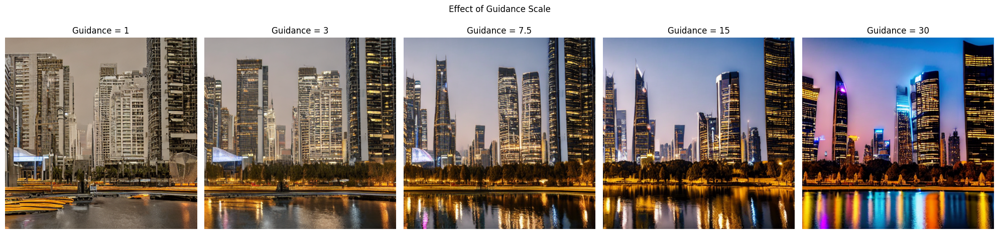

,scheduler,steps,guidance_scale,seed,generation_time_seconds,image_width,image_height,image_path,status
0,Default,30,1.0,42,4.149,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
1,Default,30,3.0,42,7.410,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
2,Default,30,7.5,42,6.526,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
3,Default,30,15.0,42,6.981,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
4,Default,30,30.0,42,7.505,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success


In [ ]:
GUIDANCE_VALUES = [1, 3, 7.5, 15, 30]

guidance_images = []
guidance_records = []

for guidance in GUIDANCE_VALUES:
    image, record = generate_image(
        steps=30,
        guidance=guidance,
        seed=42,
        scheduler_name="Default"
    )

    if image is not None:
        guidance_images.append((guidance, image))
        guidance_records.append(record)

fig, axes = plt.subplots(1, len(guidance_images), figsize=(20, 5))

if len(guidance_images) == 1:
    axes = [axes]

for ax, (guidance, img) in zip(axes, guidance_images):
    ax.imshow(img)
    ax.set_title(f"Guidance = {guidance}")
    ax.axis("off")

plt.suptitle("Effect of Guidance Scale")
plt.tight_layout()
plt.show()

guidance_df = pd.DataFrame(guidance_records)
display(guidance_df)

# **Experiment 3: Compare five sampling methods**

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

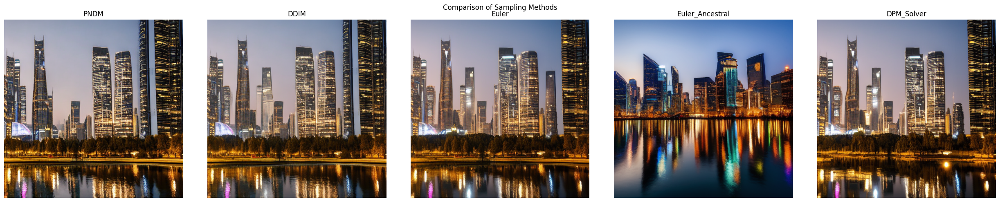

,scheduler,steps,guidance_scale,seed,generation_time_seconds,image_width,image_height,image_path,status
0,PNDM,30,7.5,42,6.886,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
1,DDIM,30,7.5,42,7.193,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
2,Euler,30,7.5,42,6.803,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
3,Euler_Ancestral,30,7.5,42,7.117,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success
4,DPM_Solver,30,7.5,42,7.198,512,512,/content/drive/MyDrive/Stable_Diffusion_Practi...,Success


In [ ]:
SCHEDULERS = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler_Ancestral": EulerAncestralDiscreteScheduler,
    "DPM_Solver": DPMSolverMultistepScheduler
}

scheduler_images = []
scheduler_records = []

original_scheduler = pipe.scheduler

for name, scheduler_class in SCHEDULERS.items():
    try:
        pipe.scheduler = scheduler_class.from_config(
            original_scheduler.config
        )

        image, record = generate_image(
            steps=30,
            guidance=7.5,
            seed=42,
            scheduler_name=name
        )

        if image is not None:
            scheduler_images.append((name, image))
            scheduler_records.append(record)

    except Exception as e:
        print(f"Scheduler {name} failed: {e}")

# Restore the original scheduler
pipe.scheduler = original_scheduler

if scheduler_images:
    fig, axes = plt.subplots(
        1, len(scheduler_images),
        figsize=(5 * len(scheduler_images), 5)
    )

    if len(scheduler_images) == 1:
        axes = [axes]

    for ax, (name, img) in zip(axes, scheduler_images):
        ax.imshow(img)
        ax.set_title(name)
        ax.axis("off")

    plt.suptitle("Comparison of Sampling Methods")
    plt.tight_layout()
    plt.show()

scheduler_df = pd.DataFrame(scheduler_records)
display(scheduler_df)

# **Experiment 4: Random seed and reproducibility**

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

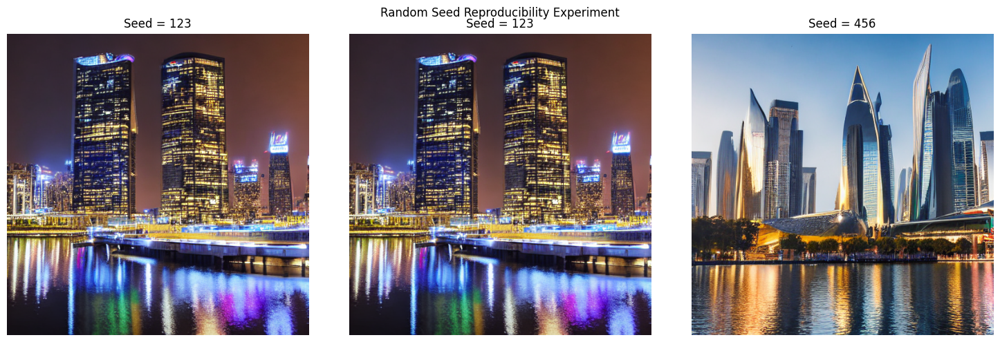

Mean pixel difference with same seed: 0.0
Mean pixel difference with different seed: 88.6434
Same-seed outputs are pixel-identical: True


In [ ]:
seed_test_images = []
seed_test_records = []

test_seeds = [123, 123, 456]

for seed in test_seeds:
    image, record = generate_image(
        steps=20,
        guidance=7.5,
        seed=seed,
        scheduler_name="Seed_Test"
    )

    if image is not None:
        seed_test_images.append((seed, image))
        seed_test_records.append(record)

fig, axes = plt.subplots(1, len(seed_test_images), figsize=(15, 5))

if len(seed_test_images) == 1:
    axes = [axes]

for ax, (seed, img) in zip(axes, seed_test_images):
    ax.imshow(img)
    ax.set_title(f"Seed = {seed}")
    ax.axis("off")

plt.suptitle("Random Seed Reproducibility Experiment")
plt.tight_layout()
plt.show()

if len(seed_test_images) >= 3:
    img1 = np.asarray(seed_test_images[0][1]).astype(np.int16)
    img2 = np.asarray(seed_test_images[1][1]).astype(np.int16)
    img3 = np.asarray(seed_test_images[2][1]).astype(np.int16)

    same_seed_difference = np.abs(img1 - img2).mean()
    different_seed_difference = np.abs(img1 - img3).mean()

    print("Mean pixel difference with same seed:",
          round(float(same_seed_difference), 4))

    print("Mean pixel difference with different seed:",
          round(float(different_seed_difference), 4))

    print(
        "Same-seed outputs are pixel-identical:",
        bool(np.array_equal(img1, img2))
    )

# **Image quality metrics using CLIP**

In [ ]:
from transformers import CLIPModel, CLIPProcessor

CLIP_MODEL_ID = "openai/clip-vit-large-patch14"

clip_model = None
clip_processor = None

try:
    clip_model = CLIPModel.from_pretrained(CLIP_MODEL_ID).to(device)
    clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)
    clip_model.eval()

    print("CLIP model loaded successfully.")

except Exception as e:
    print("CLIP unavailable; similarity scoring will be skipped.")
    print("Reason:", str(e))


def calculate_clip_similarity(image, prompt):
    if clip_model is None or clip_processor is None:
        return None

    try:
        inputs = clip_processor(
            text=[prompt],
            images=[image],
            return_tensors="pt",
            padding=True,
            truncation=True
        )

        inputs = {key: value.to(device) for key, value in inputs.items()}

        with torch.no_grad():
            image_features = clip_model.get_image_features(
                pixel_values=inputs["pixel_values"]
            )
            text_features = clip_model.get_text_features(
                input_ids=inputs["input_ids"],
                attention_mask=inputs.get("attention_mask")
            )

            # Handle model outputs consistently
            if hasattr(image_features, "pooler_output"):
                image_features = image_features.pooler_output

            if hasattr(text_features, "pooler_output"):
                text_features = text_features.pooler_output

            image_features = image_features / image_features.norm(
                dim=-1, keepdim=True
            )
            text_features = text_features / text_features.norm(
                dim=-1, keepdim=True
            )

            cosine_similarity = (
                image_features * text_features
            ).sum(dim=-1).item()

        return round(float(cosine_similarity), 4)

    except Exception as e:
        print("Could not calculate CLIP similarity:", e)
        return None


# Evaluate the generated images
metric_records = []

for record in RESULTS:
    path = record.get("image_path")

    if not path or not os.path.exists(path):
        continue

    try:
        img = Image.open(path).convert("RGB")
        similarity = calculate_clip_similarity(img, PROMPT)

        metric_records.append({
            "scheduler": record["scheduler"],
            "steps": record["steps"],
            "guidance_scale": record["guidance_scale"],
            "seed": record["seed"],
            "generation_time_seconds": record["generation_time_seconds"],
            "image_width": img.width,
            "image_height": img.height,
            "clip_similarity": similarity,
            "image_path": path
        })

    except Exception as e:
        print(f"Metric evaluation failed for {path}: {e}")

metrics_df = pd.DataFrame(metric_records)
display(metrics_df)

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

...

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded successfully.


,scheduler,steps,guidance_scale,seed,generation_time_seconds,image_width,image_height,clip_similarity,image_path
0,Default,30,7.5,42,9.586,512,512,0.2372,/content/drive/MyDrive/Stable_Diffusion_Practi...
1,Default,5,7.5,42,1.473,512,512,0.2304,/content/drive/MyDrive/Stable_Diffusion_Practi...
2,Default,10,7.5,42,2.345,512,512,0.2208,/content/drive/MyDrive/Stable_Diffusion_Practi...
3,Default,20,7.5,42,4.281,512,512,0.2347,/content/drive/MyDrive/Stable_Diffusion_Practi...
4,Default,30,7.5,42,6.765,512,512,0.2372,/content/drive/MyDrive/Stable_Diffusion_Practi...
5,Default,50,7.5,42,10.298,512,512,0.2339,/content/drive/MyDrive/Stable_Diffusion_Practi...
6,Default,30,1.0,42,4.149,512,512,0.2416,/content/drive/MyDrive/Stable_Diffusion_Practi...
7,Default,30,3.0,42,7.410,512,512,0.2307,/content/drive/MyDrive/Stable_Diffusion_Practi...
8,Default,30,7.5,42,6.526,512,512,0.2372,/content/drive/MyDrive/Stable_Diffusion_Practi...
9,Default,30,15.0,42,6.981,512,512,0.2236,/content/drive/MyDrive/Stable_Diffusion_Practi...


# **Experiment 5: Compare negative prompts**

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

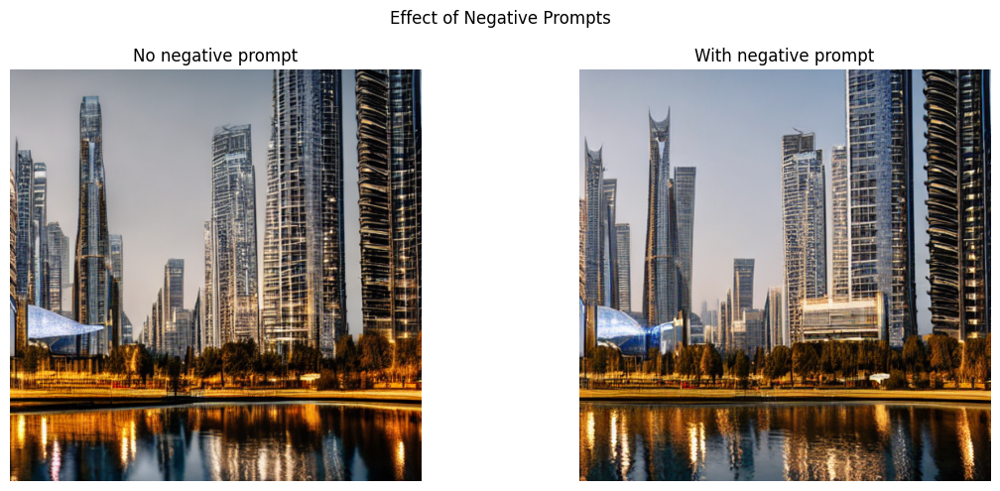

In [ ]:
negative_prompt_tests = [
    ("No negative prompt", ""),
    (
        "With negative prompt",
        "blurry, low quality, distorted objects, watermark, "
        "text, duplicate objects, artifacts"
    )
]

negative_images = []

for label, neg_prompt in negative_prompt_tests:
    image, record = generate_image(
        prompt=PROMPT,
        negative_prompt=neg_prompt,
        steps=30,
        guidance=7.5,
        seed=42,
        scheduler_name="Negative_Prompt"
    )

    if image is not None:
        negative_images.append((label, image))

fig, axes = plt.subplots(1, len(negative_images), figsize=(12, 5))

if len(negative_images) == 1:
    axes = [axes]

for ax, (label, img) in zip(axes, negative_images):
    ax.imshow(img)
    ax.set_title(label)
    ax.axis("off")

plt.suptitle("Effect of Negative Prompts")
plt.tight_layout()
plt.show()

# **Combine experiment results into comparison tables**

In [ ]:
results_df = pd.DataFrame(RESULTS)

if not results_df.empty:
    # Add CLIP similarity where available
    if not metrics_df.empty:
        metric_columns = [
            "image_path",
            "clip_similarity"
        ]

        results_df = results_df.merge(
            metrics_df[metric_columns].drop_duplicates("image_path"),
            on="image_path",
            how="left"
        )
    else:
        results_df["clip_similarity"] = np.nan

    # Keep the required comparison fields
    display_columns = [
        "scheduler",
        "steps",
        "guidance_scale",
        "seed",
        "generation_time_seconds",
        "image_width",
        "image_height",
        "clip_similarity",
        "status"
    ]

    comparison_df = results_df[
        [col for col in display_columns if col in results_df.columns]
    ]

    display(comparison_df)

    csv_path = os.path.join(RESULT_DIR, "experiment_comparison.csv")
    comparison_df.to_csv(csv_path, index=False)

    print("Comparison CSV saved to:", csv_path)

else:
    print("No successful experiment results are available yet.")

,scheduler,steps,guidance_scale,seed,generation_time_seconds,image_width,image_height,clip_similarity,status
0,Default,30,7.5,42,9.586,512,512,0.2372,Success
1,Default,5,7.5,42,1.473,512,512,0.2304,Success
2,Default,10,7.5,42,2.345,512,512,0.2208,Success
3,Default,20,7.5,42,4.281,512,512,0.2347,Success
4,Default,30,7.5,42,6.765,512,512,0.2372,Success
5,Default,50,7.5,42,10.298,512,512,0.2339,Success
6,Default,30,1.0,42,4.149,512,512,0.2416,Success
7,Default,30,3.0,42,7.410,512,512,0.2307,Success
8,Default,30,7.5,42,6.526,512,512,0.2372,Success
9,Default,30,15.0,42,6.981,512,512,0.2236,Success


Comparison CSV saved to: /content/drive/MyDrive/Stable_Diffusion_Practical_05/results/experiment_comparison.csv


# **Automatically generate observations and conclusion**

In [ ]:
def generate_conclusion(df):
    successful = df[df["status"] == "Success"].copy()

    if successful.empty:
        print("No successful generations. Review the error messages.")
        return

    print("=" * 60)
    print("AUTOMATIC EXPERIMENT OBSERVATIONS")
    print("=" * 60)

    # Generation time
    fastest = successful.loc[
        successful["generation_time_seconds"].idxmin()
    ]

    print(
        f"\nFastest recorded generation: {fastest['scheduler']}, "
        f"{fastest['steps']} steps, "
        f"guidance {fastest['guidance_scale']}, "
        f"{fastest['generation_time_seconds']} seconds."
    )

    # Steps
    step_summary = successful.groupby("steps")[
        "generation_time_seconds"
    ].mean().sort_index()

    print("\nAverage generation time by inference steps:")
    display(step_summary.to_frame("average_time_seconds"))

    # Guidance
    guidance_summary = successful.groupby("guidance_scale")[
        "generation_time_seconds"
    ].mean().sort_index()

    print("\nAverage generation time by guidance scale:")
    display(guidance_summary.to_frame("average_time_seconds"))

    # Scheduler timing
    scheduler_summary = successful.groupby("scheduler")[
        "generation_time_seconds"
    ].mean().sort_values()

    print("\nAverage generation time by scheduler:")
    display(scheduler_summary.to_frame("average_time_seconds"))

    # CLIP results, if available
    clip_available = (
        "clip_similarity" in successful.columns
        and successful["clip_similarity"].notna().any()
    )

    if clip_available:
        clip_summary = successful.dropna(
            subset=["clip_similarity"]
        ).groupby("scheduler")["clip_similarity"].mean().sort_values(
            ascending=False
        )

        print("\nMean CLIP similarity by scheduler:")
        display(clip_summary.to_frame("mean_clip_similarity"))

        print(
            "\nHighest mean CLIP similarity in this experiment:",
            clip_summary.index[0],
            f"({clip_summary.iloc[0]:.4f})"
        )
    else:
        print("\nCLIP similarity was not available for this run.")

    print("\nCONCLUSION")
    print(
        "The experiments demonstrate that inference steps, guidance scale, "
        "random seeds, negative prompts, and sampling methods affect "
        "Stable Diffusion generation. More steps generally require more "
        "computation, while guidance scale changes how closely the image "
        "follows the text prompt. Different schedulers offer different "
        "speed and image characteristics. Use the recorded measurements "
        "and visual inspection together when choosing settings."
    )


generate_conclusion(results_df)

AUTOMATIC EXPERIMENT OBSERVATIONS

Fastest recorded generation: Default, 5 steps, guidance 7.5, 1.473 seconds.

Average generation time by inference steps:


,average_time_seconds
steps,
5,1.473000
10,2.345000
20,4.895000
30,7.048071
50,10.298000



Average generation time by guidance scale:


,average_time_seconds
guidance_scale,
1.0,4.149000
3.0,7.410000
7.5,6.254353
15.0,6.981000
30.0,7.505000



Average generation time by scheduler:


,average_time_seconds
scheduler,
Seed_Test,5.099667
Default,6.119909
Euler,6.803000
PNDM,6.886000
Euler_Ancestral,7.117000
DDIM,7.193000
DPM_Solver,7.198000
Negative_Prompt,7.277000



Mean CLIP similarity by scheduler:


,mean_clip_similarity
scheduler,
Euler,0.243000
DDIM,0.239600
PNDM,0.237200
Default,0.232764
Euler_Ancestral,0.225500
DPM_Solver,0.223900
Seed_Test,0.215067



Highest mean CLIP similarity in this experiment: Euler (0.2430)

CONCLUSION
The experiments demonstrate that inference steps, guidance scale, random seeds, negative prompts, and sampling methods affect Stable Diffusion generation. More steps generally require more computation, while guidance scale changes how closely the image follows the text prompt. Different schedulers offer different speed and image characteristics. Use the recorded measurements and visual inspection together when choosing settings.


# **Save all final results**



In [ ]:
# Save complete records, including failed attempts where recorded
all_results_path = os.path.join(RESULT_DIR, "all_experiment_records.csv")

pd.DataFrame(RESULTS).to_csv(
    all_results_path,
    index=False
)

if not metrics_df.empty:
    metrics_path = os.path.join(RESULT_DIR, "image_quality_metrics.csv")
    metrics_df.to_csv(metrics_path, index=False)
    print("Image metrics saved to:", metrics_path)

print("All experiment records saved to:", all_results_path)
print("Generated images folder:", IMAGE_DIR)
print("Results folder:", RESULT_DIR)

Image metrics saved to: /content/drive/MyDrive/Stable_Diffusion_Practical_05/results/image_quality_metrics.csv
All experiment records saved to: /content/drive/MyDrive/Stable_Diffusion_Practical_05/results/all_experiment_records.csv
Generated images folder: /content/drive/MyDrive/Stable_Diffusion_Practical_05/generated_images
Results folder: /content/drive/MyDrive/Stable_Diffusion_Practical_05/results


# **Conclusion**
Use your actual outputs to complete this conclusion:

Inference steps: Describe how image detail changed as the number of steps increased and whether generation time increased.
Guidance scale: Describe which setting followed the prompt best and whether very high guidance affected the image.
Sampling method: Compare the appearance and generation time of the schedulers tested.